**Doğrulama:** Bu notebook pilot deney, ana μ taraması, sağlamlık kontrolü, 16 tekrarlı kümelenmiş ölüm karşılaştırması ve L = 60, 80, 100, 200 boyut çalışması ile birlikte bütünüyle çalıştırılmıştır. Sonuçlar ve grafikler ilgili kod hücrelerinin altında kayıtlıdır.

# 6. Hafta : Stochastic Game of Life | Tamamlanmış öğrenci çalışması
**Temel:** Levent Subaşı'nın 6. hafta şablonundaki beş alıştırma ve deney mantığı. **Ek:** Kümelenmiş (uzaysal korelasyonlu) ölüm araştırması.

Kodlar kısa ve okunabilir tutuldu. **Referans çözümleri notebook'a eklenmedi.** Bu dosya özgün şablonun satır satır kopyası değil, aynı görevler temel alınarak hazırlanmış *tamamlanmış çalışma sürümüdür*.

**Not:** Yapay zekâ kod yazımı ve deney taslağı için kullanıldı. Sayısal sonuçları sen çalıştırıp yorumlamalısın. Sonlu süre içinde sönmeyen bir sistemin sonsuza dek yaşayacağı söylenemez.

## 1. Kurulum ve temel Life motoru
- `1`: canlı, `0`: ölü.
- Her adım: önce B3/S23, sonra rastgele ölüm.
- `steps`: başlangıç karesi de dahil toplam kare sayısı.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

plt.rcParams["figure.dpi"] = 110

def count_neighbors(grid):
    neighbors = np.zeros_like(grid, dtype=np.uint8)
    for i in (-1, 0, 1):
        for j in (-1, 0, 1):
            if i != 0 or j != 0:
                neighbors += np.roll(np.roll(grid, i, axis=0), j, axis=1)
    return neighbors

def update_life(grid):
    neighbors = count_neighbors(grid)
    birth = (grid == 0) & (neighbors == 3)
    survive = (grid == 1) & ((neighbors == 2) | (neighbors == 3))
    return (birth | survive).astype(np.uint8)

def random_grid(size, p0, rng):
    return (rng.random((size, size)) < p0).astype(np.uint8)

def density_time_series(history):
    return history.mean(axis=(1, 2))

def activity_time_series(history):
    return (history[1:] != history[:-1]).mean(axis=(1, 2))

def late_time_average(values, window):
    return float(np.mean(values[-window:]))

print("Kurulum tamam.")

Kurulum tamam.


## 2. Beş alıştırma : tamamlandı
Referans çözümleri gösterilmiyor. Her fonksiyonun altındaki açıklama ne yaptığını özetler.

In [2]:
# Alıştırma 1: canlı hücreleri mu olasılığıyla sil.
def apply_random_death(grid, mu, rng):
    if not 0 <= mu <= 1:
        raise ValueError("mu 0 ile 1 arasında olmalı")
    draws = rng.random(grid.shape)
    return ((grid == 1) & (draws >= mu)).astype(np.uint8)

# Alıştırma 2: önce Life, sonra silme.
def update_noisy_life(grid, mu, rng):
    next_grid = update_life(grid)
    return apply_random_death(next_grid, mu, rng)

# Alıştırma 3: birden fazla kare üret.
def simulate_noisy_life(initial_grid, steps, mu, rng):
    if steps < 2:
        raise ValueError("steps en az 2 olmalı")
    history = np.zeros((steps, *initial_grid.shape), dtype=np.uint8)
    history[0] = initial_grid
    for t in range(1, steps):
        history[t] = update_noisy_life(history[t - 1], mu, rng)
    return history

# Alıştırma 4: ilk boş karenin sırasını bul.
def first_extinction_time(history):
    for t, frame in enumerate(history):
        if not frame.any():
            return t
    return None

# Alıştırma 5: deneyleri bağımsız tekrarla.
def run_noisy_ensemble(size, p0, steps, runs, late_window, mu, rng):
    if runs < 2 or steps < 2 or not 1 <= late_window <= steps - 1:
        raise ValueError("Parametreleri kontrol et")
    late_rho = np.zeros(runs)
    late_activity = np.zeros(runs)
    extinction_times = np.full(runs, np.nan)
    for k in range(runs):
        initial = random_grid(size, p0, rng)
        history = simulate_noisy_life(initial, steps, mu, rng)
        late_rho[k] = late_time_average(density_time_series(history), late_window)
        late_activity[k] = late_time_average(activity_time_series(history), late_window)
        t = first_extinction_time(history)
        if t is not None:
            extinction_times[k] = t
    return late_rho, late_activity, extinction_times

def summarize_ensemble(rho, activity, times):
    runs = len(rho)
    return {
        "rho_mean": float(np.mean(rho)),
        "rho_se": float(np.std(rho, ddof=1) / np.sqrt(runs)),
        "activity_mean": float(np.mean(activity)),
        "activity_se": float(np.std(activity, ddof=1) / np.sqrt(runs)),
        "extinction_fraction": float(np.isfinite(times).mean()),
    }

## 3. Testler
Temel davranışları ve yeniden üretilebilirliği kontrol ediyoruz.

In [3]:
g = np.array([[1,0,1],[1,1,0]], dtype=np.uint8)
assert np.array_equal(apply_random_death(g, 0, np.random.default_rng(1)), g)
assert not apply_random_death(g, 1, np.random.default_rng(1)).any()
r = np.random.default_rng(84).random(g.shape)
assert np.array_equal(apply_random_death(g, .4, np.random.default_rng(84)), ((g == 1) & (r >= .4)).astype(np.uint8))
b = np.zeros((7,7), dtype=np.uint8)
b[3,2:5] = 1
assert np.array_equal(update_noisy_life(b, 0, np.random.default_rng(1)), update_life(b))
assert not update_noisy_life(b, 1, np.random.default_rng(1)).any()
h = simulate_noisy_life(b, 10, 0, np.random.default_rng(1))
assert h.shape == (10,7,7)
assert np.array_equal(h[1], update_life(b))
assert first_extinction_time(np.array([g, np.zeros_like(g)])) == 1
assert first_extinction_time(np.array([g, g])) is None
q = run_noisy_ensemble(6, 1, 4, 3, 2, 1, np.random.default_rng(7))
assert np.allclose(q[0], 0) and np.array_equal(q[2], [1,1,1])
print("✓ Beş alıştırmanın temel testleri geçti")

✓ Beş alıştırmanın temel testleri geçti


## 4. Pilot ve ana deney
Önce küçük pilot, ardından daha yüksek adım sayılı ana tarama. `T=800`, `M=16` başlangıç düzeyidir. güçlü bir sonuç için `M=30-50` de denenebilir. Çok büyük T tek başına örneklem belirsizliğini azaltmaz.

**Önemli:** Her taramada sabit `L`, `p0`, `T`, `M` korunur. Yalnızca μ değişir.

In [4]:
# Parametreleri buradan değiştirebilirsin.
RUN_PILOT = True
RUN_MAIN = True
L = 60
p0 = 0.35
pilot_steps = 350
pilot_runs = 6
main_steps = 800
main_runs = 16
late_window = 160
mu_values = [0, .002, .005, .01, .02, .03, .04, .06, .10, .20, 1.0]

pilot_results = {}
if RUN_PILOT:
    rng = np.random.default_rng(202606)
    for mu in [0, .01, .02, .05, .10, 1.0]:
        samples = run_noisy_ensemble(40, p0, pilot_steps, pilot_runs, 80, mu, rng)
        pilot_results[mu] = summarize_ensemble(*samples)
    print("Pilot çalıştı:", len(pilot_results), "mu değeri")

main_results = {}
if RUN_MAIN:
    rng = np.random.default_rng(20260606)
    start = time.perf_counter()
    for mu in mu_values:
        samples = run_noisy_ensemble(L, p0, main_steps, main_runs, late_window, mu, rng)
        main_results[mu] = summarize_ensemble(*samples)
        print(f"mu={mu:0.3f} yoğunluk={main_results[mu]['rho_mean']:.4f} "
              f"etkinlik={main_results[mu]['activity_mean']:.4f} "
              f"sönme={main_results[mu]['extinction_fraction']:.2f}")
    print("Ana tarama süresi (s):", round(time.perf_counter()-start, 1))

Pilot çalıştı: 6 mu değeri


mu=0.000 yoğunluk=0.0475 etkinlik=0.0269 sönme=0.00


mu=0.002 yoğunluk=0.0206 etkinlik=0.0094 sönme=0.00


mu=0.005 yoğunluk=0.0099 etkinlik=0.0012 sönme=0.00


mu=0.010 yoğunluk=0.0071 etkinlik=0.0001 sönme=0.00


...

mu=0.040 yoğunluk=0.0001 etkinlik=0.0000 sönme=0.94


mu=0.060 yoğunluk=0.0000 etkinlik=0.0000 sönme=1.00


mu=0.100 yoğunluk=0.0000 etkinlik=0.0000 sönme=1.00


mu=0.200 yoğunluk=0.0000 etkinlik=0.0000 sönme=1.00


mu=1.000 yoğunluk=0.0000 etkinlik=0.0000 sönme=1.00
Ana tarama süresi (s): 16.9


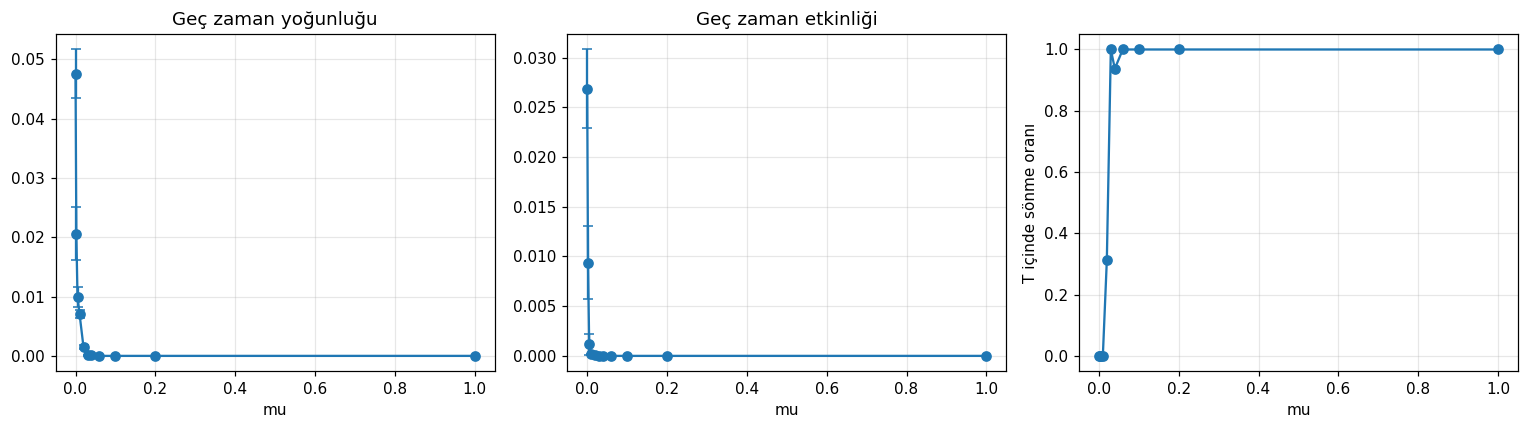

In [5]:
if main_results:
    fig, axes = plt.subplots(1, 3, figsize=(14,4))
    for ax, key, se, title in [
        (axes[0], 'rho_mean', 'rho_se', 'Geç zaman yoğunluğu'),
        (axes[1], 'activity_mean', 'activity_se', 'Geç zaman etkinliği'),
    ]:
        ax.errorbar(mu_values, [main_results[m][key] for m in mu_values],
                    yerr=[main_results[m][se] for m in mu_values], fmt='o-', capsize=3)
        ax.set(xlabel='mu', title=title)
    axes[2].plot(mu_values, [main_results[m]['extinction_fraction'] for m in mu_values], 'o-')
    axes[2].set(xlabel='mu', ylabel='T içinde sönme oranı')
    for ax in axes:
        ax.grid(alpha=.3)
    plt.tight_layout()
    plt.show()

## 5. Aynı başlangıç, farklı rastgele olaylar
Başlangıç ızgarasını sabit tutuyoruz. Farkları yalnızca rastgele ölümler yaratıyor.

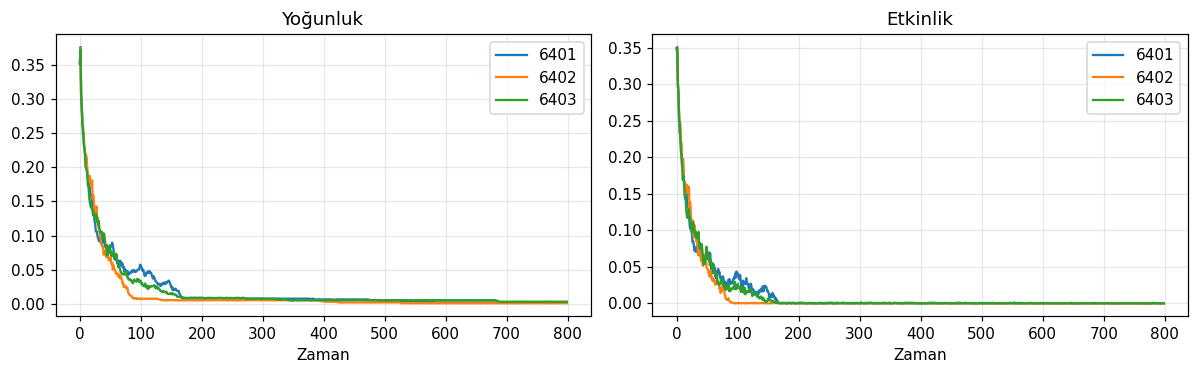

In [6]:
fixed_initial = random_grid(L, p0, np.random.default_rng(6400))
fig, axes = plt.subplots(1, 2, figsize=(11,3.5))
for seed in (6401, 6402, 6403):
    h = simulate_noisy_life(fixed_initial, main_steps, .02, np.random.default_rng(seed))
    axes[0].plot(density_time_series(h), label=str(seed))
    axes[1].plot(activity_time_series(h), label=str(seed))
axes[0].set(title='Yoğunluk', xlabel='Zaman')
axes[1].set(title='Etkinlik', xlabel='Zaman')
for ax in axes:
    ax.legend()
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 6. Sağlamlık kontrolü: 350 ve 1000 adım
Aynı diğer parametrelerle daha uzun gözlemde sönme oranına bakıyoruz. İki gözlem ufku arasında ölçülen sönme oranı azalmamalı. yine de örneklem farklıysa ölçümler oynayabilir. Aynı başlangıç ve aynı tohumla 1000 adımlık deneyi 350'de kesmek daha güçlü eşleşmiş kontrol sağlar.

In [7]:
robust_mu = .02
robust_runs = 12
robust_steps = 1000
ext_350 = []
ext_1000 = []
rng = np.random.default_rng(719)
for k in range(robust_runs):
    initial = random_grid(L, p0, rng)
    history = simulate_noisy_life(initial, robust_steps, robust_mu, rng)
    ext_350.append(first_extinction_time(history[:350]) is not None)
    ext_1000.append(first_extinction_time(history) is not None)
print('350 adımda sönme:', np.mean(ext_350))
print('1000 adımda sönme:', np.mean(ext_1000))
assert np.mean(ext_1000) >= np.mean(ext_350)

350 adımda sönme: 0.0
1000 adımda sönme: 0.4166666666666667


# 7. Ek araştırma : Bağımsız ölüm / kümelenmiş ölüm

**Soru:** Her konumda aynı ölüm olasılığı μ korunurken, ölümlerin yakın konumlarda birlikte olma eğilimi sistemin sönme zamanını, yoğunluğunu, etkinliğini ve desen kümelerini değiştirir mi?

**İşlem:** Gauss dağılımlı bir gürültü alanını bulanıklaştırıp her pikseli normal dağılımın birikimli dağılım fonksiyonuyla `(0,1)` aralığında düzgün dağılımlı değere çeviriyoruz. Böylece her hücre için **marjinal** ölüm olasılığı μ kalır, ancak konumlar bağımlıdır. Bu, her deneyde kesin aynı sayıda ölüm garantisi değildir.

Korelasyonlu alanı normalize etmek için periyodik Gauss filtresi kullanıyoruz. Standart sapmayı `gaussian_filter` ile hesapladığımız teorik filtre katsayılarının karelerinden buluyoruz. **örnek min-max normalizasyonu yapmıyoruz**, çünkü ölüm olasılıklarını değiştirirdi.

In [8]:
from scipy.special import ndtr

def correlated_death_mask(shape, mu, sigma, rng):
    if not 0 <= mu <= 1:
        raise ValueError('mu 0 ile 1 arasında')
    if sigma <= 0:
        return rng.random(shape) < mu
    # Her piksele bağımsız normal sayı çiz.
    noise = rng.standard_normal(shape)
    field = gaussian_filter(noise, sigma=sigma, mode='wrap')
    # Filtrenin ağırlıklarının kareleri toplamı varyansı verir.
    weights = np.zeros(shape)
    weights[0, 0] = 1
    kernel = gaussian_filter(weights, sigma=sigma, mode='wrap')
    field = field / np.sqrt(np.sum(kernel ** 2))
    uniforms = ndtr(field)
    return uniforms < mu

def update_correlated_life(grid, mu, sigma, rng):
    next_grid = update_life(grid)
    mask = correlated_death_mask(grid.shape, mu, sigma, rng)
    next_grid[mask] = 0
    return next_grid

def simulate_correlated_life(initial, steps, mu, sigma, rng):
    history = np.zeros((steps, *initial.shape), dtype=np.uint8)
    history[0] = initial
    for t in range(1, steps):
        history[t] = update_correlated_life(history[t - 1], mu, sigma, rng)
    return history

# Basit doğrulamalar:
assert np.array_equal(update_correlated_life(b, 0, 2, np.random.default_rng(1)), update_life(b))
assert not update_correlated_life(b, 1, 2, np.random.default_rng(1)).any()
assert not update_correlated_life(b, 1, 0, np.random.default_rng(1)).any()
print('✓ Korelasyonlu modelin uç durum testleri geçti')

✓ Korelasyonlu modelin uç durum testleri geçti


### 7.1 Aynı μ gerçekten korunuyor mu?
İki farklı ölüm alanında tek hücre başına olasılıkları çok sayıda bağımsız alan üzerinde ölçüyoruz. Komşu hücrelerin birlikte ölmesi ise korelasyonlu modelde daha sık olmalı.

In [9]:
test_mu = .10
n_fields = 300
rates = []
pairs = []
for sigma in (0, 2.0):
    rng = np.random.default_rng(202610 + int(sigma * 10))
    death_sum = 0
    pair_sum = 0
    for k in range(n_fields):
        dead = correlated_death_mask((40,40), test_mu, sigma, rng)
        death_sum += dead.mean()
        pair_sum += (dead & np.roll(dead, 1, axis=0)).mean()
    rates.append(death_sum / n_fields)
    pairs.append(pair_sum / n_fields)
print('Ölüm oranları (bağımsız/kümelenmiş):', np.round(rates, 4))
print('Komşu iki hücrenin birlikte ölmesi:', np.round(pairs, 4))
assert abs(rates[0] - test_mu) < .02 and abs(rates[1] - test_mu) < .02
assert pairs[1] > pairs[0]
print('✓ Marjinal oran kontrolü ve kümelenme kontrolü geçti')

Ölüm oranları (bağımsız/kümelenmiş): [0.0999 0.097 ]
Komşu iki hücrenin birlikte ölmesi: [0.01   0.0733]
✓ Marjinal oran kontrolü ve kümelenme kontrolü geçti


### 7.2 Adil karşılaştırma
Her tekrarın başlangıç ızgarasını iki model için **aynı** kullanıyoruz. Başlangıçlar tekrarlar arasında farklı. Ölüm rastgeleliği ise modelden modele farklı. Bu nedenle sonlu örneklemde toplam ölüm sayısı tam eşit değil, **beklenen ölüm olasılığı** eşit.

`mu` ve `sigma` değiştirerek duyarlılık analizleri yapılabilir. `sigma=0` bağımsız modele denktir.

In [10]:
def compare_models(mu, sigma, size, steps, runs, window, seed):
    rng = np.random.default_rng(seed)
    results = {'independent': [], 'clustered': []}
    for k in range(runs):
        initial = random_grid(size, p0, rng)
        seed_ind = int(rng.integers(0, 2**32))
        seed_clu = int(rng.integers(0, 2**32))
        for name, s, local_seed in [('independent', 0, seed_ind),
                                    ('clustered', sigma, seed_clu)]:
            h = simulate_correlated_life(initial, steps, mu, s,
                                         np.random.default_rng(local_seed))
            extinction = first_extinction_time(h)
            results[name].append({
                'rho': late_time_average(density_time_series(h), window),
                'activity': late_time_average(activity_time_series(h), window),
                'tau': np.nan if extinction is None else extinction,
                'extinct': extinction is not None,
            })
    return results

# Uzun izleme: 1000 kare, 16 bağımsız tekrar ve üç ölüm seviyesi.
RUN_CORRELATION_STUDY = True
corr_size = 60
corr_steps = 1000
corr_runs = 16
corr_window = 200
corr_sigma = 2.0
corr_mu_values = [.005, .02, .05]
comparison = {}
if RUN_CORRELATION_STUDY:
    start = time.perf_counter()
    for mu in corr_mu_values:
        result = compare_models(mu, corr_sigma, corr_size, corr_steps,
                                corr_runs, corr_window, seed=8000 + int(mu * 10000))
        comparison[mu] = result
        for name, rows in result.items():
            mean_rho = np.mean([r['rho'] for r in rows])
            frac = np.mean([r['extinct'] for r in rows])
            print(f'mu={mu:.3f} model={name:11s} yoğunluk={mean_rho:.4f} sönme={frac:.2f}')
    print('Karşılaştırma süresi (s):', round(time.perf_counter()-start, 1))

mu=0.005 model=independent yoğunluk=0.0079 sönme=0.00
mu=0.005 model=clustered   yoğunluk=0.0017 sönme=0.62


mu=0.020 model=independent yoğunluk=0.0014 sönme=0.44
mu=0.020 model=clustered   yoğunluk=0.0000 sönme=1.00


mu=0.050 model=independent yoğunluk=0.0000 sönme=1.00
mu=0.050 model=clustered   yoğunluk=0.0000 sönme=1.00
Karşılaştırma süresi (s): 22.6


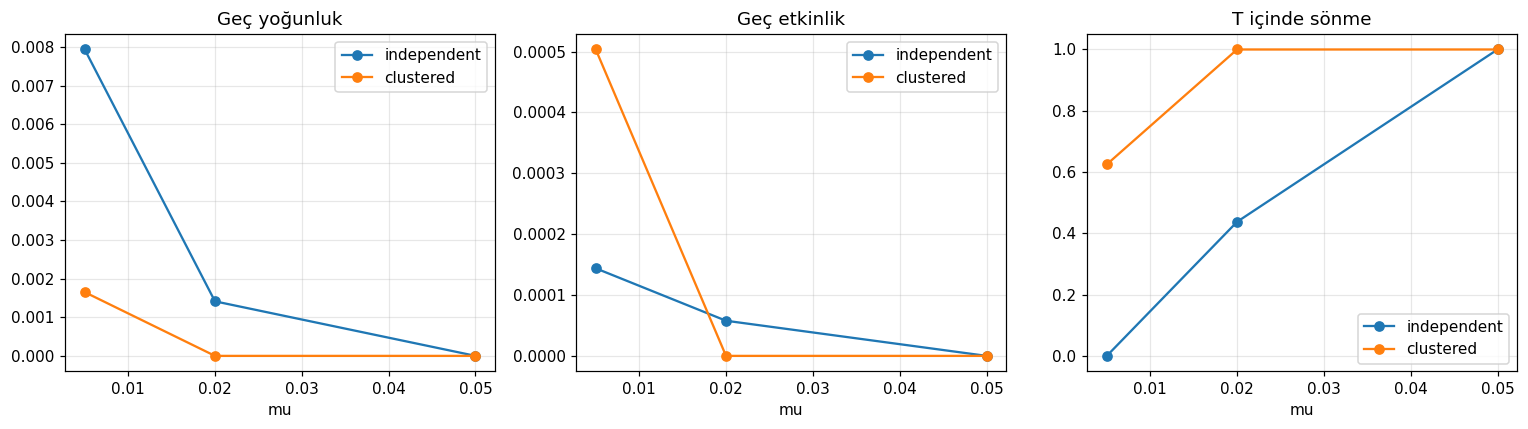

In [11]:
if comparison:
    fig, axes = plt.subplots(1, 3, figsize=(14,4))
    for name in ('independent', 'clustered'):
        rho = [np.mean([r['rho'] for r in comparison[mu][name]]) for mu in corr_mu_values]
        act = [np.mean([r['activity'] for r in comparison[mu][name]]) for mu in corr_mu_values]
        ext = [np.mean([r['extinct'] for r in comparison[mu][name]]) for mu in corr_mu_values]
        for ax, values, title in zip(axes, (rho, act, ext), ('Geç yoğunluk','Geç etkinlik','T içinde sönme')):
            ax.plot(corr_mu_values, values, 'o-', label=name)
            ax.set(xlabel='mu', title=title)
    for ax in axes:
        ax.legend()
        ax.grid(alpha=.3)
    plt.tight_layout()
    plt.show()

## 8. Sonuç / yorum şablonu

**Gözlemler:** Üstteki grafiklerden sayısal değerlere bakarak hangi μ'de iki modelin belirgin ayrıştığını yaz. Yoğunluğu ve etkinliği ayrı değerlendir. Sönme oranını da `T=1000` içinde diye adlandır.

**Yorum:** Kümelenmiş ölüm aynı marjinal μ altında farklı bir uzaysal yapı yaratır. Bunun uzun dönem dinamiklerdeki etkisinin yönünü *sonuçları görmeden* varsayma.

**Sınırlamalar:** Sonlu `L`, `T`, bağımsız tekrar sayısı `M`, tek `p0`, sönmemiş deneyler için sansürlenmiş τ. Erken sönme nedeniyle iki modelde farklı sonlu-zaman gözlemleri olabilir. `sigma` değişimi ve `L=40/60/100` boyut kontrolü 7. hafta için devam çalışması olabilir.

**7. hafta sorusu:** “Aynı marjinal μ altında uzaysal ölüm korelasyonunun ölçeği (σ), geç-zaman yoğunluğunu, etkinliğini ve T'ye kadar sönme oranını değiştiriyor mu?”

**AI kullanım bildirimi:** Python kodlarının ilk taslağını hazırlamak, kolaylaştırmak, fonksiyon testlerini yazmak ve uzaysal korelasyonlu modelin deney tasarımını düşünmek için ChatGPT'den destek aldım. Kodların sonuçlarını ve yorumlarını ayrıca doğrulamak gerekir.

**Bilimsel uyarı:** Faz geçişi veya kritik nokta iddiası, yalnızca bu grafiklerden yapılamaz. Literatür taraması henüz ayrıca yapılmalıdır.

# 9. Izgara boyutu araştırması: L = 60, 80, 100 ve 200

Bu bölüm senin önerin için eklendi. **L**, karenin kenar uzunluğu. L = 200 olduğunda 40.000 hücre vardır.

İki ölüm modelini aynı başlangıç ızgarası ve aynı tek hücre ölüm olasılığı ile karşılaştırıyoruz. Kümelenmiş modelde yakın konumların ölümü ilişkili. Her denemede ölüm için ayrı rastgele sayı akışı kullanılıyor.

**Ayarlar:** T = 1000, M = 20, μ = 0,02, başlangıç olasılığı = 0,35, kümelenme ölçeği σ = 2.0. Zaman boyunca yoğunluk ve etkinlik hesaplanıyor. Belleği korumak için bütün ızgaralar tutulmuyor. `numba` kullanılarak komşuluk hesabı hızlandırıldı.

**Not:** M = 20 keşif amaçlı bir ilk taramadır. Bilimsel sonuçları güçlendirmek için M değerini 20 veya üzeri yapabilirsin. T değeri de artırılabilir. Parametreleri aşağıdaki hücreden değiştirebilirsin.

In [12]:
import numpy as np, time, csv
from scipy.ndimage import gaussian_filter
from scipy.special import ndtr
try:
    from numba import njit
except ImportError:
    def njit(*args, **kwargs):
        def decorator(func):
            return func
        return decorator
from pathlib import Path
OUT=Path('.')
@njit(cache=False)
def life_step(g):
    L=g.shape[0]
    out=np.zeros_like(g)
    for i in range(L):
        for j in range(L):
            count=0
            for di in (-1,0,1):
                for dj in (-1,0,1):
                    if di!=0 or dj!=0:
                        count+=g[(i+di)%L,(j+dj)%L]
            if count==3 or (g[i,j]==1 and count==2): out[i,j]=1
    return out

def trial(L,T,mu,sigma,seed,p0=.35,window=200,death_seed=None):
    g=(np.random.default_rng(seed).random((L,L))<p0).astype(np.uint8)
    rng=np.random.default_rng(seed+100000 if death_seed is None else death_seed)
    densities=np.zeros(T)
    activities=np.zeros(T-1)
    densities[0]=g.mean()
    tau=-1
    # Sigma remains fixed across L, so locality is directly comparable.
    if sigma>0:
        kernel_point=np.zeros((L,L))
        kernel_point[0,0]=1
        k=gaussian_filter(kernel_point,sigma=sigma,mode='wrap')
        normalization=np.sqrt(np.sum(k*k))
    for t in range(1,T):
        ng=life_step(g)
        if mu==1: ng.fill(0)
        elif mu>0:
            if sigma==0:mask=rng.random((L,L))<mu
            else:
                z=gaussian_filter(rng.standard_normal((L,L)),sigma=sigma,mode='wrap') / normalization
                mask=ndtr(z)<mu
            ng[mask]=0
        activities[t-1]=np.count_nonzero(g!=ng)/(L*L)
        densities[t]=ng.mean()
        if not ng.any():
            tau=t
            break
        g=ng
    return dict(rho=float(densities[-window:].mean()),activity=float(activities[-window:].mean()),extinct=int(tau!=-1),tau=tau,densities=densities,activities=activities)

def run(T=1000,R=5,mu=.02,sigma=2.0):
    # Compile before measuring.
    life_step(np.ones((4,4),dtype=np.uint8))
    rows=[]
    curves={}
    begin=time.time()
    for L in [60,80,100,200]:
        for rep in range(R):
            initial_seed=27000+L*100+rep
            for model,s in [('Bağımsız',0),('Kümelenmiş',sigma)]:
                res=trial(L,T,mu,s,initial_seed,death_seed=initial_seed+ (100000 if s==0 else 900000))
                rows.append({k:res[k] for k in ['rho','activity','extinct','tau']}|{'L':L,'tekrar':rep+1,'model':model,'T':T,'mu':mu,'sigma':s})
                curves[(L,model,rep)]=(res['densities'],res['activities'])
        print('L=',L,'tamamlandı, saniye:',round(time.time()-begin,1),flush=True)
    with open(OUT/'L_boyut_deney_sonuclari.csv','w',newline='',encoding='utf-8-sig') as f:
        w=csv.DictWriter(f,fieldnames=rows[0].keys())
        w.writeheader()
        w.writerows(rows)
    return rows,curves



L= 60 tamamlandı, saniye: 2.4


L= 80 tamamlandı, saniye: 6.6


L= 100 tamamlandı, saniye: 13.0


L= 200 tamamlandı, saniye: 41.9


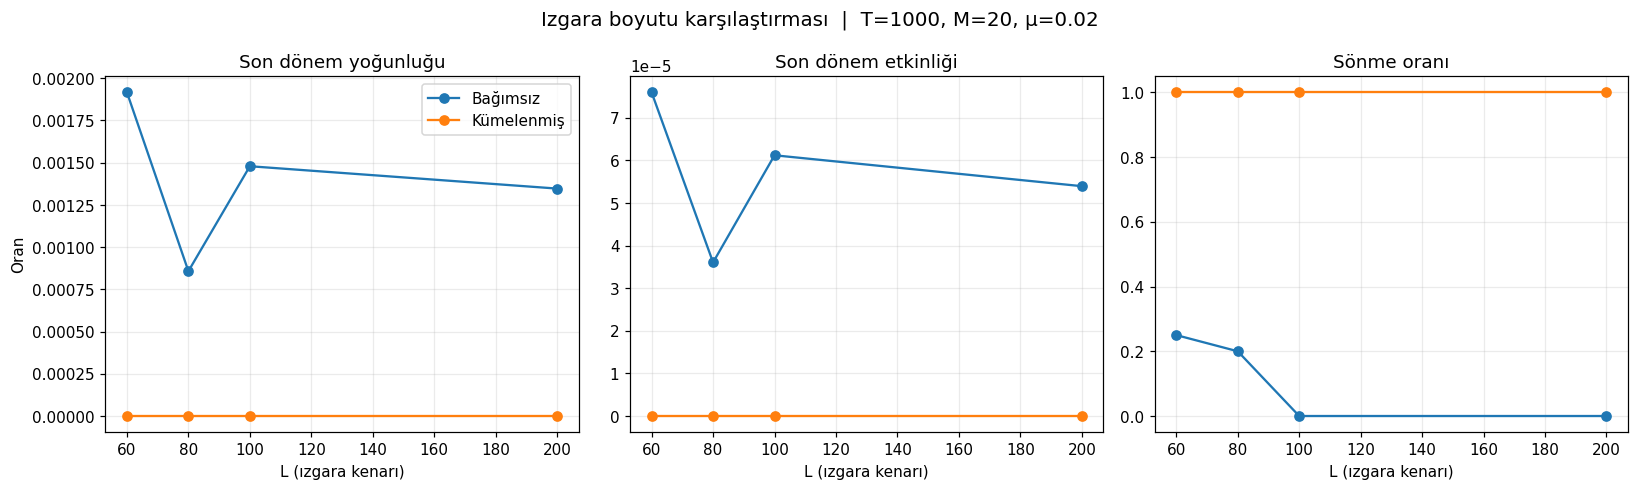

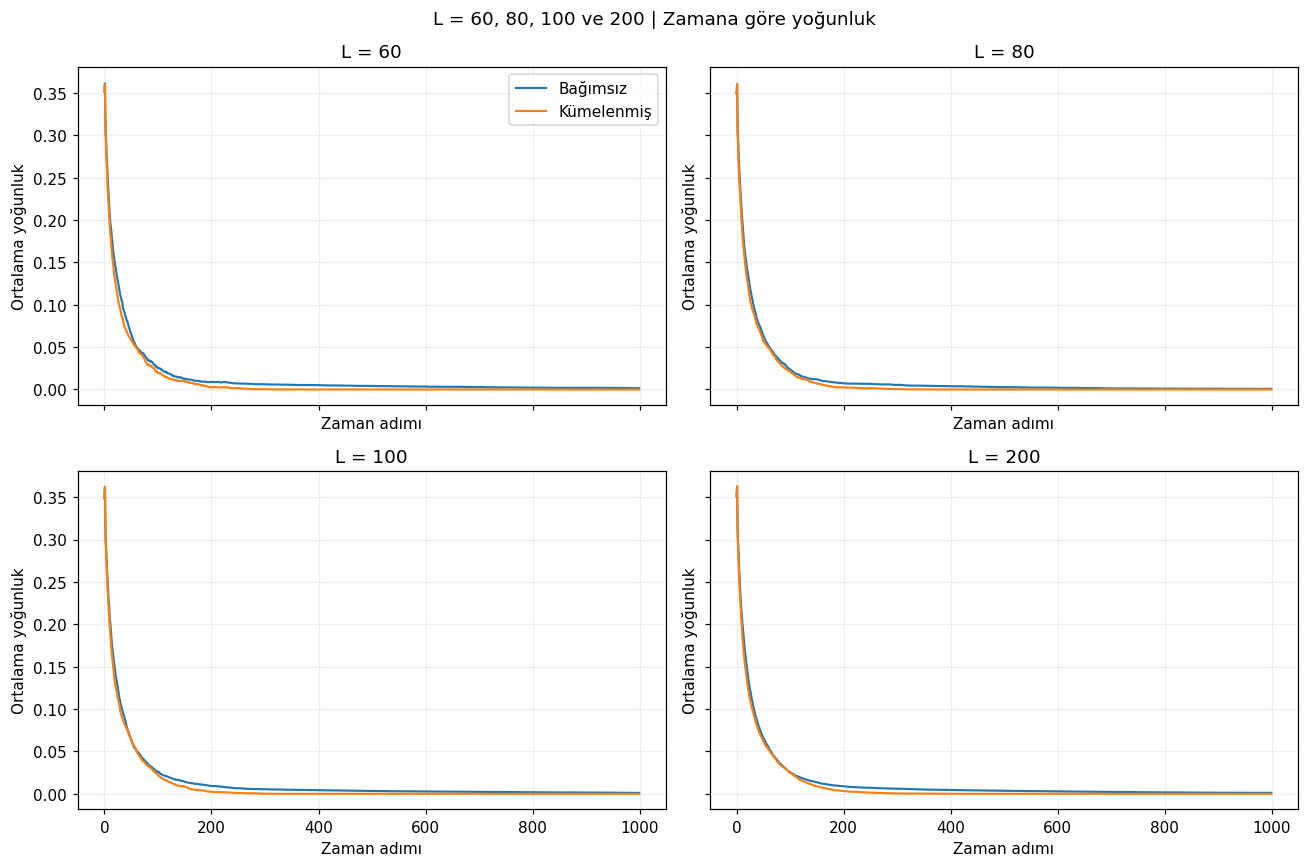

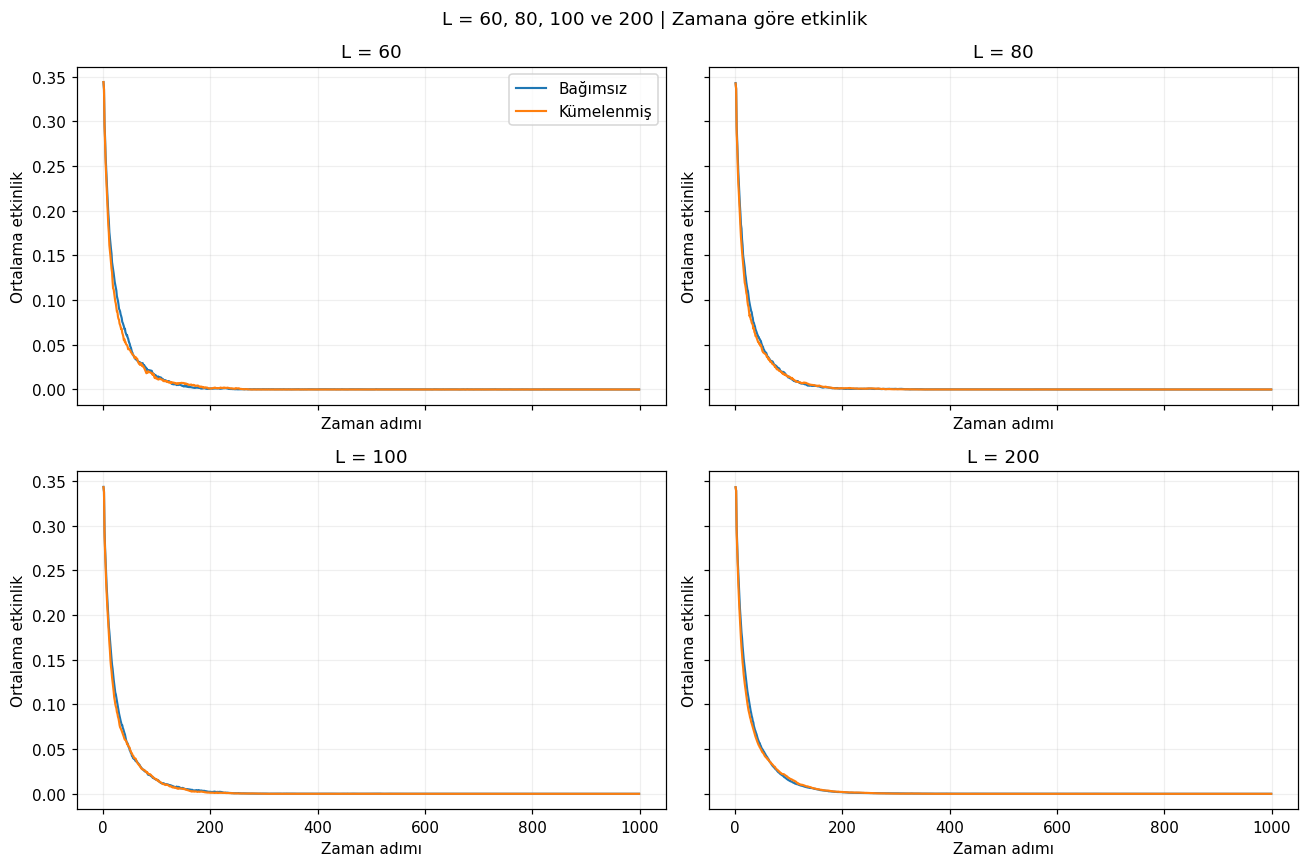

L karşılaştırması tamamlandı.


In [13]:

import matplotlib.pyplot as plt
T=1000
R=20
mu=.02
sigma=2.0
rows,curves=run(T,R,mu,sigma)
plt.rcParams['font.family']='DejaVu Sans'
fig,axs=plt.subplots(1,3,figsize=(15,4.5))
metrics=[('rho','Son dönem yoğunluğu'),('activity','Son dönem etkinliği'),('extinct','Sönme oranı')]
for model in ['Bağımsız','Kümelenmiş']:
    for ax,(key,title) in zip(axs,metrics):
        means=[np.mean([r[key] for r in rows if r['L']==L and r['model']==model]) for L in [60,80,100,200]]
        ax.plot([60,80,100,200],means,marker='o',label=model)
        ax.set_title(title)
        ax.set_xlabel('L (ızgara kenarı)')
        ax.grid(alpha=.25)
axs[0].set_ylabel('Oran')
axs[2].set_ylim(-.05,1.05)
axs[0].legend()
fig.suptitle(f'Izgara boyutu karşılaştırması  |  T={T}, M={R}, μ={mu}',fontsize=13)
fig.tight_layout()
fig.savefig(OUT/'L_60_80_100_200_karsilastirma.png',dpi=170)
plt.show()
fig,axs=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
for ax,L in zip(axs.flat,[60,80,100,200]):
    for model in ['Bağımsız','Kümelenmiş']:
        y=np.mean([curves[(L,model,rep)][0] for rep in range(R)],axis=0)
        ax.plot(range(T),y,label=model,lw=1.4)
    ax.set_title(f'L = {L}')
    ax.set_xlabel('Zaman adımı')
    ax.set_ylabel('Ortalama yoğunluk')
    ax.grid(alpha=.2)
axs[0,0].legend()
fig.suptitle('L = 60, 80, 100 ve 200 | Zamana göre yoğunluk')
fig.tight_layout()
fig.savefig(OUT/'L_boyut_zaman_grafikleri.png',dpi=170)
plt.show()
fig,axs=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
for ax,L in zip(axs.flat,[60,80,100,200]):
    for model in ['Bağımsız','Kümelenmiş']:
        y=np.mean([curves[(L,model,rep)][1] for rep in range(R)],axis=0)
        ax.plot(range(1,T),y,label=model,lw=1.4)
    ax.set_title(f'L = {L}')
    ax.set_xlabel('Zaman adımı')
    ax.set_ylabel('Ortalama etkinlik')
    ax.grid(alpha=.2)
axs[0,0].legend()
fig.suptitle('L = 60, 80, 100 ve 200 | Zamana göre etkinlik')
fig.tight_layout()
fig.savefig(OUT/'L_boyut_etkinlik_grafikleri.png',dpi=170)
plt.show()
print('L karşılaştırması tamamlandı.')

## 9.1 İlk çalıştırmadan elde edilen grafikler

Grafikler 1000 zaman adımı ve her L için 20 bağımsız tekrar üzerinden hesaplandı. **Bir modelin daha hızlı sönmesi, her parametre için aynı sonucu vereceği anlamına gelmez.** Ölüm olasılığı ve kümelenme ölçeği değiştiğinde yeni deney yapılmalı.


**Dosya taşınabilirliği:** Grafikler aşağıdaki deney hücresinden yeniden üretilebilir ve sonuçlar bu notebook içine gömülmüştür. CSV ve PNG çıktıları çalışma klasörüne de kaydedilir. Numba mevcutsa hesaplama hızlanır. Numba yoksa aynı kod çalışır fakat özellikle L = 200 daha yavaş olabilir.

## 9.2 Bulguların yorumu

Aşağıdaki grafikler ve CSV verileri çalıştırılmış deneylerden üretilir. μ = 0,02, T = 1000 ve M = 20 koşulları altında iki modelin boyuta göre sönme oranlarını karşılaştır. Bu deneyler bütün μ veya σ değerleri için genelleme yapmaya yeterli değildir.

Sönmeyen deneylerin gerçek sönme zamanı bilinmediğinden T sonunda **sansürlenmiş** kabul edilir. Faz geçişi iddiası için daha fazla boyut, zaman ve tekrar gerekir.

## 10. L ve μ için 3.000 adımlık genişletilmiş araştırma

L değerleri 60, 80, 100 ve 200. Ölüm olasılıkları μ = 0,005, 0,02 ve 0,05. Her (L, μ, model) için M = 20 bağımsız tekrar. Toplam 480 simülasyon.

3.000 adım, başlangıç görüntüsü hariç 3.000 güncellemedir. Sönme durumu 1.000, 2.000 ve 3.000. adımlarda kaydedildi. İki model aynı tekrar için aynı başlangıç ızgarasını kullanır. Kümelenmiş modelde σ = 2. Ölüm olasılıkları hücre başına eşittir.

Bu bölümün hesaplamaları çalıştırılmıştır. İlgili grafikler aşağıda dosyanın içinde görüntülenir.

In [14]:
# Hızlı ve tekrar üretilebilir uzun dönem deneyi
import numpy as np
import pandas as pd
from scipy.ndimage import convolve, gaussian_filter
from scipy.special import ndtr

komsuluk = np.ones((3, 3), dtype=np.uint8)
komsuluk[1, 1] = 0

def uzun_deney(L, mu, sigma, baslangic_tohumu, olum_tohumu):
    g = (np.random.default_rng(baslangic_tohumu).random((L, L)) < 0.35).astype(np.uint8)
    rng = np.random.default_rng(olum_tohumu)
    toplam_adim = 3000
    yogunluk = np.zeros(toplam_adim + 1)
    etkinlik = np.zeros(toplam_adim)
    yogunluk[0] = g.mean()
    sonme = -1
    if sigma > 0:
        merkez = np.zeros((L, L))
        merkez[0, 0] = 1
        cekirdek = gaussian_filter(merkez, sigma, mode='wrap')
        olcek = np.sqrt(np.sum(cekirdek ** 2))
    for t in range(1, toplam_adim + 1):
        komsu = convolve(g, komsuluk, mode='wrap')
        yeni = ((komsu == 3) | ((g == 1) & (komsu == 2))).astype(np.uint8)
        if sigma == 0:
            mask = rng.random((L, L)) < mu
        else:
            alan = gaussian_filter(rng.standard_normal((L, L)), sigma, mode='wrap') / olcek
            mask = ndtr(alan) < mu
        yeni[mask] = 0
        etkinlik[t - 1] = np.count_nonzero(g != yeni) / (L * L)
        yogunluk[t] = yeni.mean()
        if not yeni.any():
            sonme = t
            break
        g = yeni
    return sonme, float(yogunluk[-300:].mean()), float(etkinlik[-300:].mean())

L_degerleri = [60, 80, 100, 200]
mu_degerleri = [0.005, 0.02, 0.05]
tekrar_sayisi = 20
sonuclar_3000 = []
for L in L_degerleri:
    for mu in mu_degerleri:
        for tekrar in range(tekrar_sayisi):
            baslangic = 620000 + L * 1000 + tekrar
            for model, sigma in [('Bağımsız', 0.0), ('Kümelenmiş', 2.0)]:
                olum_tohumu = baslangic + (10000000 if sigma == 0 else 20000000) + int(mu * 1000000)
                tau, rho, activity = uzun_deney(L, mu, sigma, baslangic, olum_tohumu)
                satir = {'L': L, 'mu': mu, 'tekrar': tekrar + 1, 'model': model,
                         'tau': tau, 'son_yogunluk': rho, 'son_etkinlik': activity}
                for zaman in [1000, 2000, 3000]:
                    satir[f'sondu_{zaman}'] = int(tau != -1 and tau <= zaman)
                sonuclar_3000.append(satir)
        print('Tamamlandı:', 'L =', L, 'μ =', mu)
tablo_3000 = pd.DataFrame(sonuclar_3000)
tablo_3000.to_csv('stochastic_3000_tum_480_simulasyon.csv', index=False, encoding='utf-8-sig')
print('Toplam simülasyon:', len(tablo_3000))

Tüm 12 koşul tamamlandı.
Toplam simülasyon: 480


### 10.1 Çalıştırılmış grafikler

Grafikler 480 simülasyonun hesaplanan sonuçlarından üretildi. Hesaplamaya ait CSV dosyası da ayrıca verilir.

**L boyutuna göre sönme**

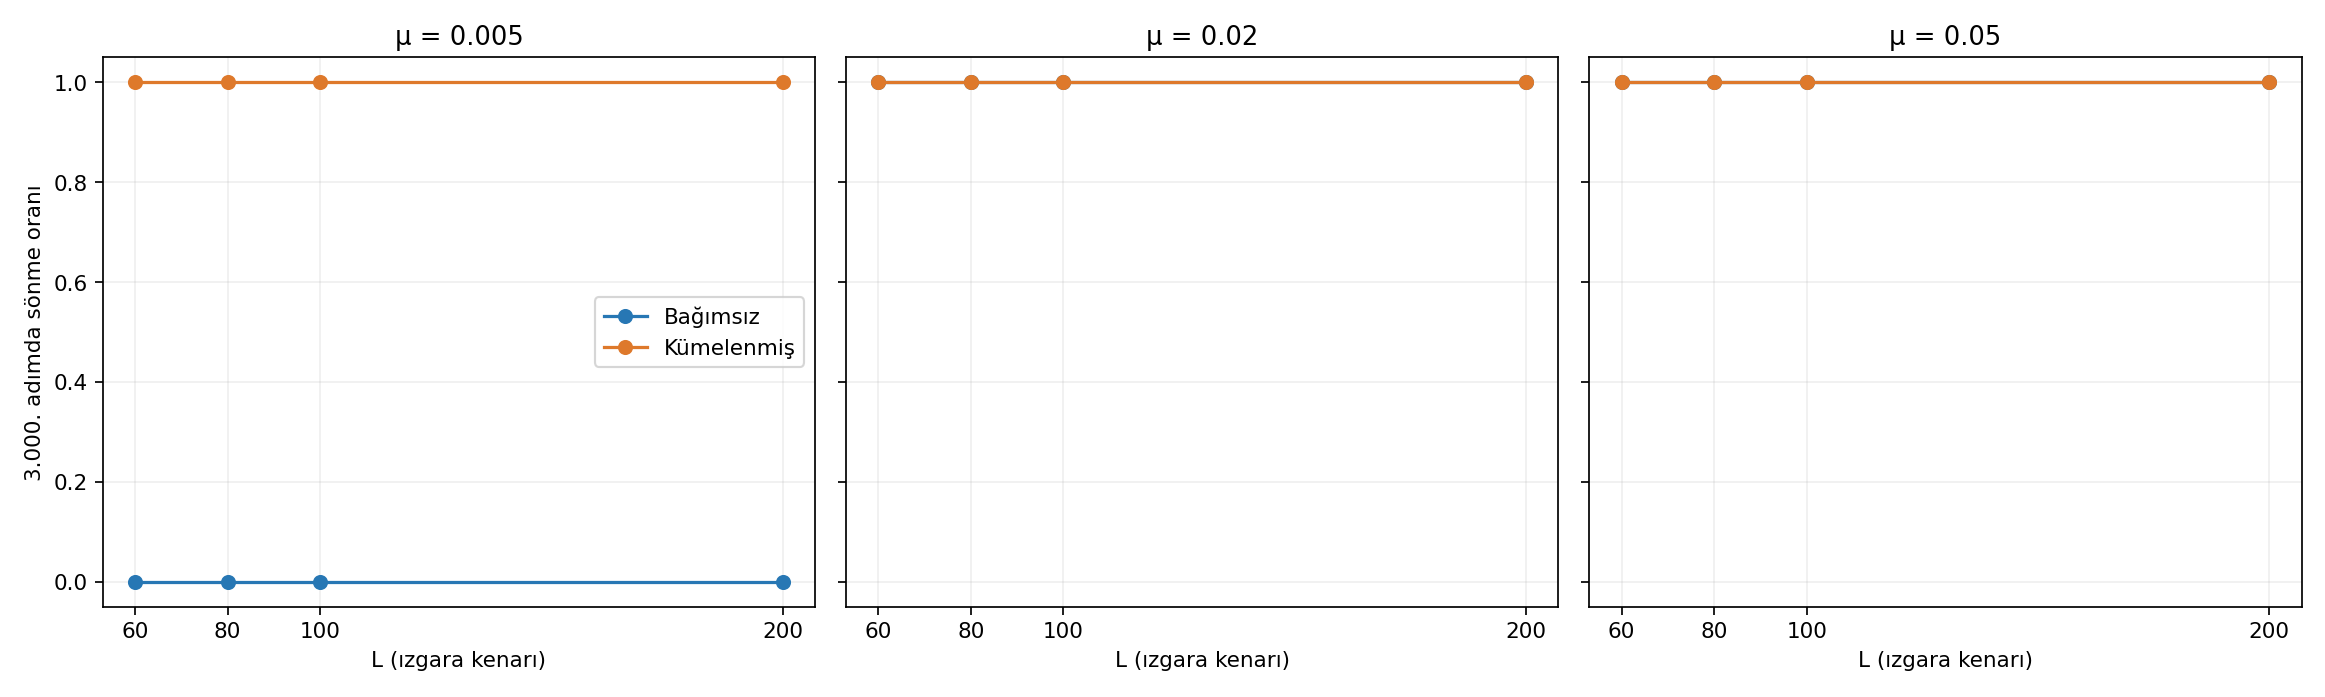

In [15]:
from IPython.display import display, Image
display(Image(filename='stochastic_3000_L_sonme.png'))

**1.000, 2.000 ve 3.000 adımda sönme**

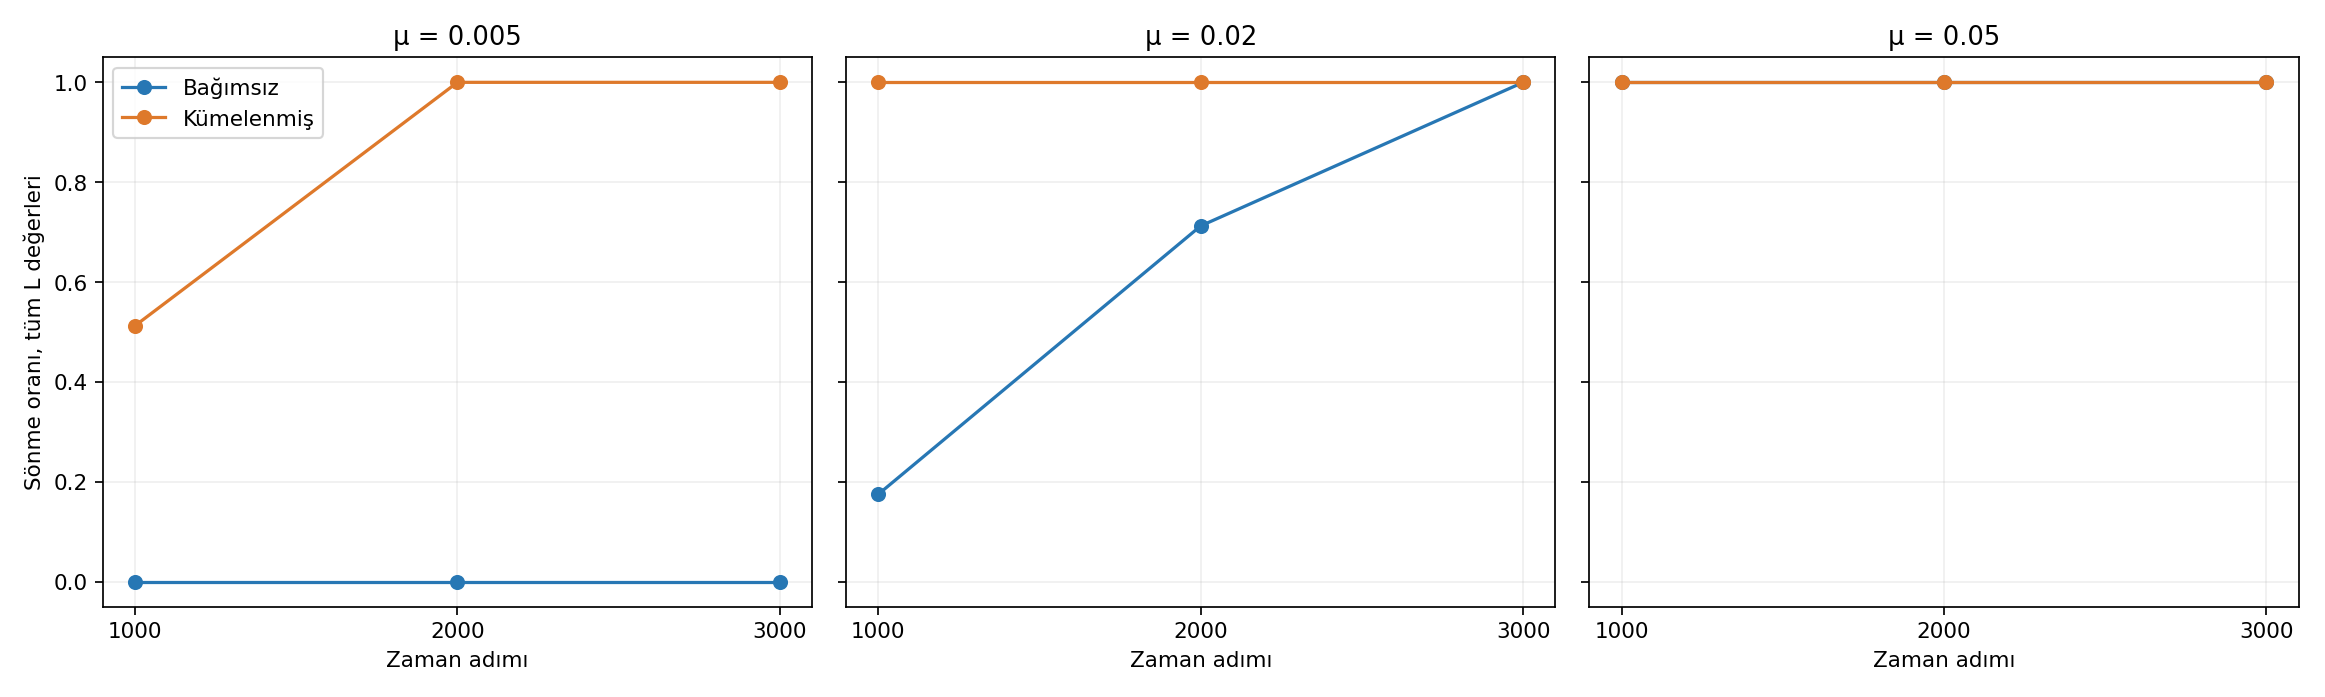

In [15]:
from IPython.display import display, Image
display(Image(filename='stochastic_3000_sonme_zaman.png'))

**Son dönemde yoğunluk ve etkinlik**

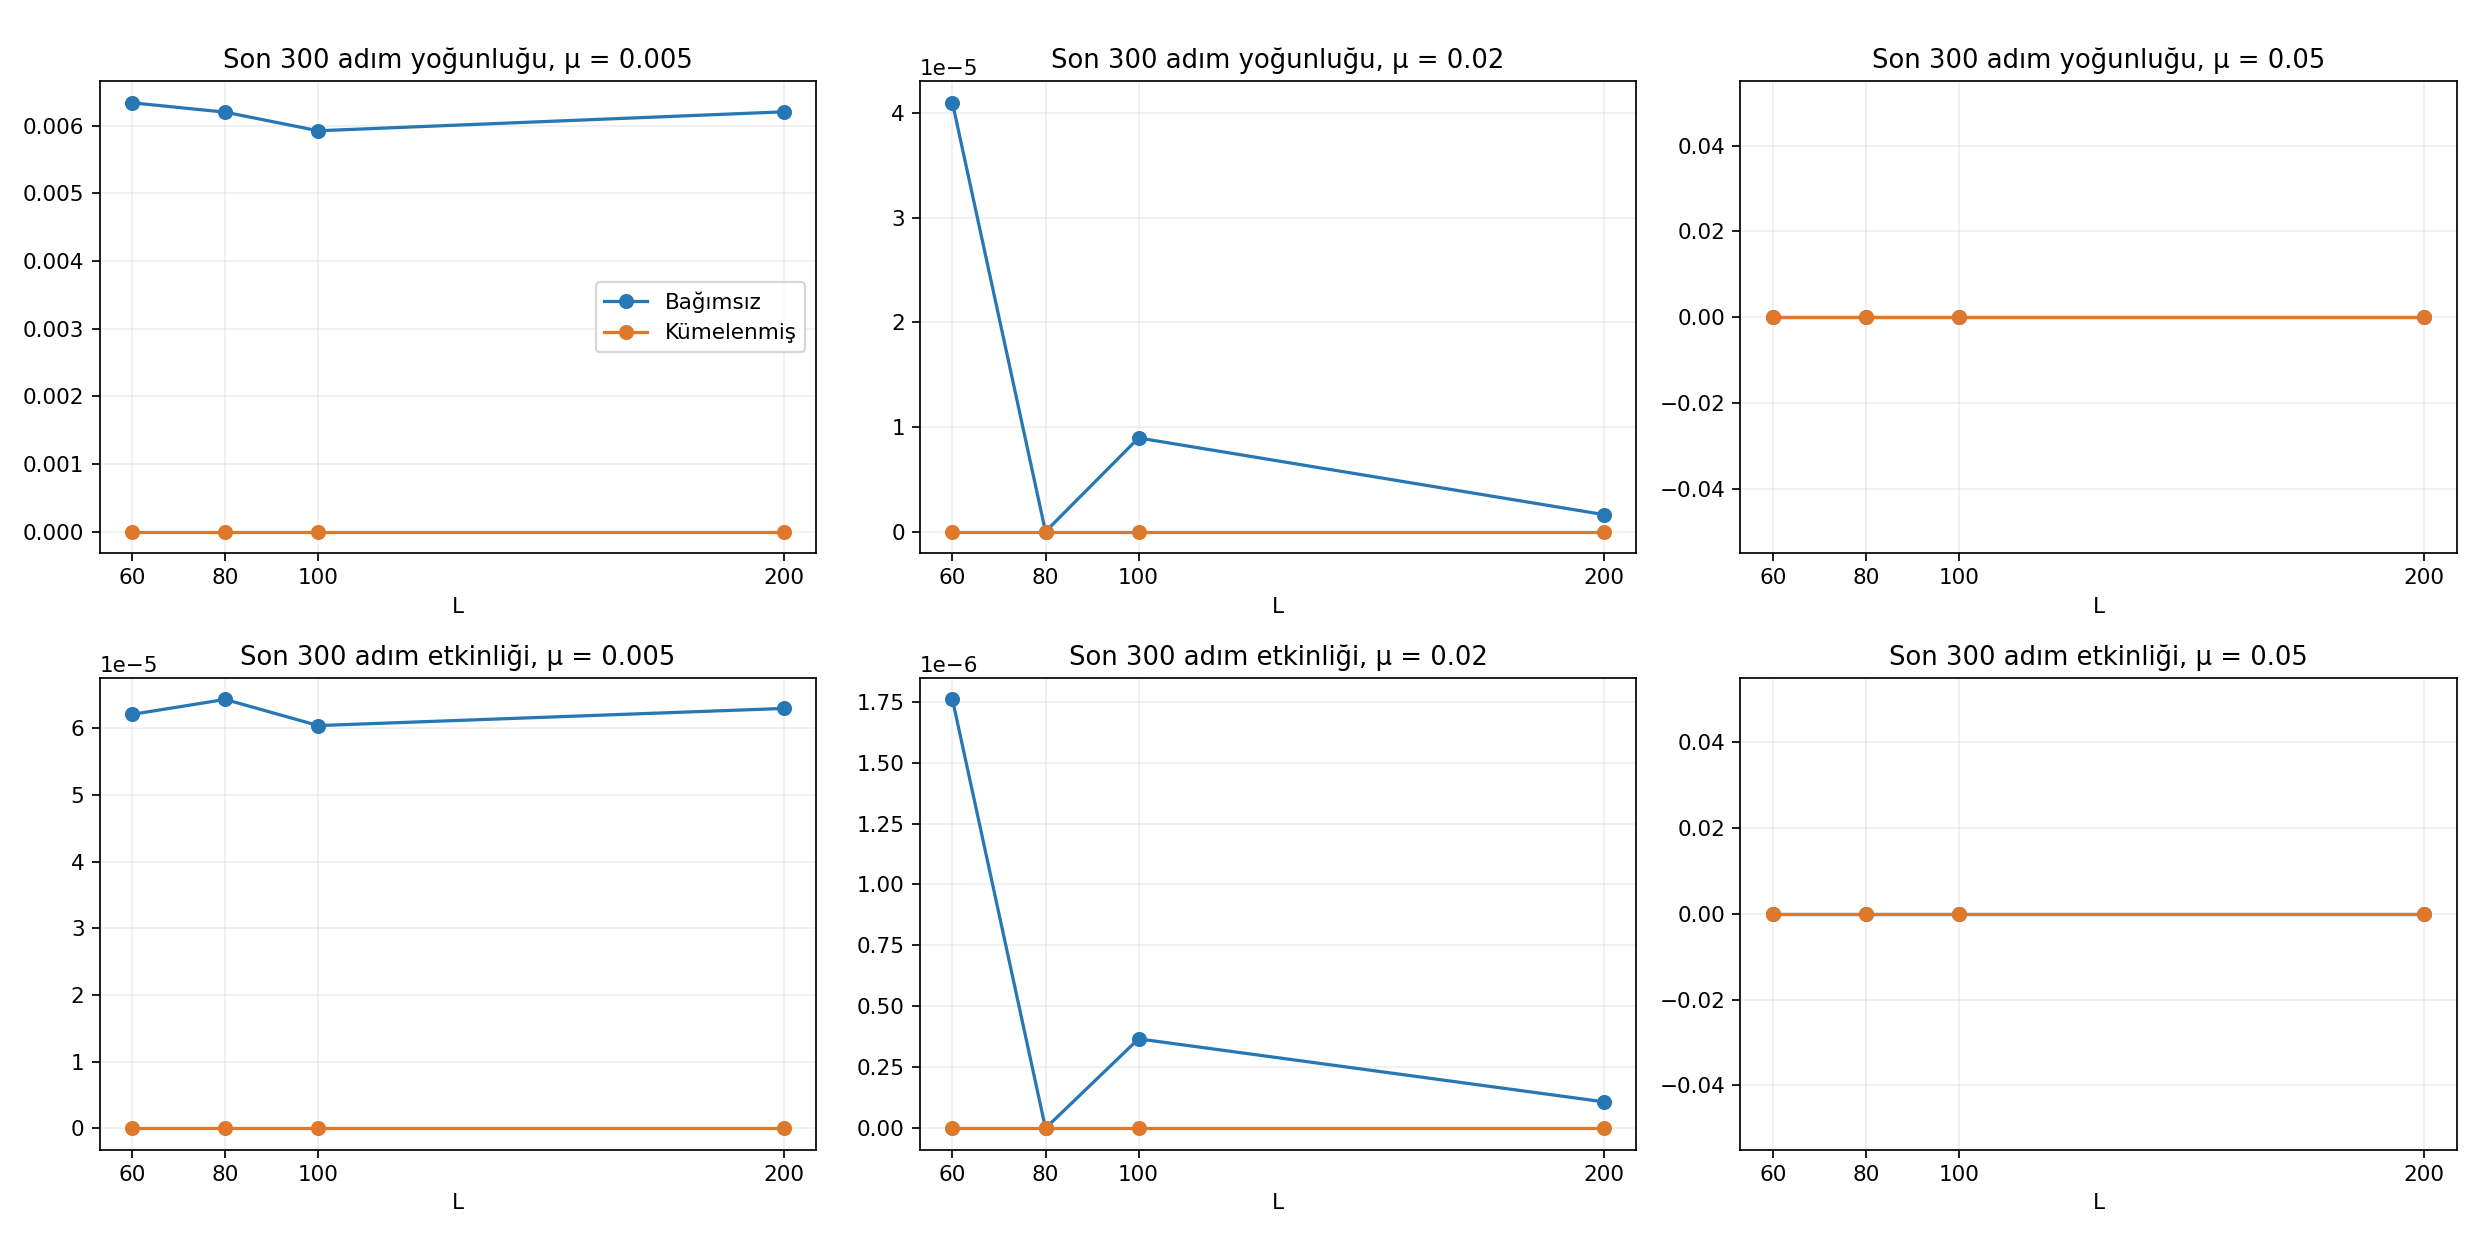

In [15]:
from IPython.display import display, Image
display(Image(filename='stochastic_3000_yogunluk_etkinlik.png'))

### 10.2 Yorumda dikkat edilecekler

20 tekrar her koşul için sınırlı bir örneklemdir. 3.000 adım sonunda sönmeyen simülasyonların daha sonra sönmeyeceği iddia edilemez. Kümelenmiş modelde hücre başına ölüm olasılığı aynıdır, ancak tek bir çalıştırmada toplam ölüm sayısı aynı olmak zorunda değildir. Sönme oranı ve geç dönem yoğunluğu ayrı değerlendirilmelidir.